<div dir="rtl">

# 02 · עיבוד מקדים ומודלי סיווג

**הסדר (כדי למנוע Data Leakage):**
1. לפצל ל־train/test **לפני הכול**, עם `stratify`.
2. כל העיבוד (השלמת חסרים, One-hot, Scaling) בתוך `Pipeline`, כך שהוא לומד רק מה־train.
3. להשוות מודלים ושיטות איזון ב־Cross-validation על ה־train בלבד.
4. רק בסוף: הערכה אחת על ה־test.

> כל תא קוד במחברת נכתב בעזרת Claude, ולכן מסומן `### CODE BY CLAUDE ###` לפי הנחיות המרצה.

</div>

In [1]:
### CODE BY CLAUDE ###
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # כדי שאפשר יהיה לייבא את src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import (load_raw, add_features, get_xy, build_preprocessor, FIGURES,
                      RANDOM_STATE, TARGET, SEVERITY_NAMES, CATEGORICAL, NUMERIC, BINARY)

sns.set_theme(style="whitegrid")
FIGURES.mkdir(exist_ok=True)
SEV_ORDER = ["קטלנית", "קשה", "קלה"]
SEV_COLORS = ["#a3262c", "#e08a2c", "#7a8aa0"]

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (f1_score, recall_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, make_scorer)
from sklearn.preprocessing import label_binarize
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

# שמות בעברית לטבלאות התוצאות
COLS_HE = {"model": "מודל", "balance": "איזון", "f1_macro": "F1-macro", "recall_fatal": "Recall קטלנית",
           "pr_auc": "PR-AUC", "accuracy": "Accuracy"}
BALANCE_HE = {"none": "בלי טיפול", "class_weight": "class_weight", "smote": "SMOTE"}
####

<div dir="rtl">

## 1. פיצול train/test
בלי 1,235 התאונות שאין בהן פרטי דרך (ראו `01_eda`, סעיף 7): נשארות 7,080.
80/20, עם `stratify=y`: בשני החלקים יהיה אותו אחוז של קטלניות (כ־5.7%).

</div>

In [2]:
### CODE BY CLAUDE ###
X, y = get_xy(load_raw())
# מחלקות כ־0/1/2 (‏XGBoost דורש תוויות שמתחילות ב־0): ‏0 = קטלנית, 1 = קשה, 2 = קלה
y = y - 1
CLASS_NAMES = SEV_ORDER

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, " test:", X_test.shape)
print(pd.DataFrame({"% ב־train": y_train.value_counts(normalize=True).sort_index().mul(100).round(1),
                    "% ב־test": y_test.value_counts(normalize=True).sort_index().mul(100).round(1)},
                   ).set_axis(CLASS_NAMES))
####

train: (5664, 33)  test: (1416, 33)
        % ב־train  % ב־test
קטלנית        5.7       5.6
קשה          21.2      21.3
קלה          73.1      73.1


<div dir="rtl">

## 2. העיבוד המקדים
- **קטגוריות (28):** השלמת חסר בערך השכיח, ואז One-hot. קטגוריה שמופיעה פחות מ־10 פעמים מאוחדת ל"נדירה" (`min_frequency=10`), כדי לא ליצור עמודות כמעט ריקות.
- **מספריות (X, Y):** השלמה בחציון, ו־Scaling (רק למודלים שרגישים לגודל: לוגיסטית, KNN, MLP).
- **דגלים (3):** עוברים כמו שהם.

</div>

In [3]:
### CODE BY CLAUDE ###
prep = build_preprocessor().fit(X_train)
print("מספר פיצ'רים אחרי One-hot:", prep.transform(X_train.head()).shape[1])
####

מספר פיצ'רים אחרי One-hot: 224


<div dir="rtl">

## 3. המדדים
- **F1-macro (המדד הראשי):** ממוצע של F1 בכל מחלקה. כך הקטלנית שוקלת כמו האחרות, למרות שהיא 5% מהדאטה.
- **Recall של קטלנית:** כמה מהתאונות הקטלניות המודל תפס.
- **PR-AUC (macro):** איכות הדירוג של המודל, בלי תלות בסף. מתאים לדאטה לא מאוזן.
- Accuracy מוצג רק להשוואה, לא לבחירת מודל.

</div>

In [4]:
### CODE BY CLAUDE ###
def pr_auc_macro(y_true, proba):
    y_bin = label_binarize(y_true, classes=[0, 1, 2])
    return average_precision_score(y_bin, proba, average="macro")

SCORING = {
    "f1_macro": "f1_macro",
    "recall_fatal": make_scorer(recall_score, labels=[0], average="macro"),
    "pr_auc": make_scorer(pr_auc_macro, response_method="predict_proba"),
    "accuracy": "accuracy",
}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
####

<div dir="rtl">

## 4. ניסוי 1: 6 מודלים × 3 שיטות איזון
- **בלי טיפול.**
- **class_weight:** טעות על מחלקה קטנה "עולה" יותר (`class_weight="balanced"`, או `sample_weight` ב־XGBoost). ל־MLP ול־KNN אין אפשרות כזו.
- **SMOTE:** **בתוך** הפייפליין של imblearn, כך שבכל fold הוא רץ רק על חלק האימון.

</div>

In [5]:
### CODE BY CLAUDE ###
def make_models(balance):
    cw = "balanced" if balance == "class_weight" else None
    models = {
        "LogisticRegression": LogisticRegression(max_iter=2000, class_weight=cw, random_state=RANDOM_STATE),
        "DecisionTree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight=cw, random_state=RANDOM_STATE),
        "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight=cw, n_jobs=-1, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                 eval_metric="mlogloss", n_jobs=-1, random_state=RANDOM_STATE),
    }
    if balance != "class_weight":   # לשני המודלים האלה אין class_weight
        models["MLP"] = MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True,
                                      max_iter=300, random_state=RANDOM_STATE)
        models["KNN"] = KNeighborsClassifier(n_neighbors=15)
    return models

def make_pipeline(model, balance):
    steps = [("prep", build_preprocessor())]
    if balance == "smote":
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("clf", model))
    return Pipeline(steps)

rows = []
for balance in ["none", "class_weight", "smote"]:
    for name, model in make_models(balance).items():
        params = {}
        if balance == "class_weight" and name == "XGBoost":
            params = {"clf__sample_weight": compute_sample_weight("balanced", y_train)}
        res = cross_validate(make_pipeline(model, balance), X_train, y_train, cv=CV,
                             scoring=SCORING, params=params, n_jobs=1)
        rows.append({"model": name, "balance": BALANCE_HE[balance],
                     **{m: res[f"test_{m}"].mean() for m in SCORING}})
        print(f"{name:20s} {BALANCE_HE[balance]:13s} F1-macro={rows[-1]['f1_macro']:.3f}  Recall קטלנית={rows[-1]['recall_fatal']:.3f}")

results = pd.DataFrame(rows).round(3).sort_values("f1_macro", ascending=False)
results.rename(columns=COLS_HE).to_csv(FIGURES / "experiment1_results.csv", index=False, encoding="utf-8-sig")
results.rename(columns=COLS_HE)
####

LogisticRegression   בלי טיפול     F1-macro=0.423  Recall קטלנית=0.137


DecisionTree         בלי טיפול     F1-macro=0.374  Recall קטלנית=0.044


RandomForest         בלי טיפול     F1-macro=0.325  Recall קטלנית=0.016


XGBoost              בלי טיפול     F1-macro=0.393  Recall קטלנית=0.090


MLP                  בלי טיפול     F1-macro=0.345  Recall קטלנית=0.041


KNN                  בלי טיפול     F1-macro=0.334  Recall קטלנית=0.025


... (7 outputs left out)

XGBoost              SMOTE         F1-macro=0.360  Recall קטלנית=0.078


MLP                  SMOTE         F1-macro=0.396  Recall קטלנית=0.146


KNN                  SMOTE         F1-macro=0.298  Recall קטלנית=0.461


,מודל,איזון,F1-macro,Recall קטלנית,PR-AUC,Accuracy
8,RandomForest,class_weight,0.457,0.392,0.452,0.626
9,XGBoost,class_weight,0.447,0.396,0.455,0.611
6,LogisticRegression,class_weight,0.437,0.508,0.451,0.580
11,DecisionTree,SMOTE,0.430,0.237,0.418,0.635
10,LogisticRegression,SMOTE,0.428,0.495,0.439,0.568
0,LogisticRegression,בלי טיפול,0.423,0.137,0.479,0.732
12,RandomForest,SMOTE,0.419,0.125,0.456,0.721
14,MLP,SMOTE,0.396,0.146,0.404,0.648
3,XGBoost,בלי טיפול,0.393,0.090,0.475,0.733
7,DecisionTree,class_weight,0.376,0.498,0.407,0.471


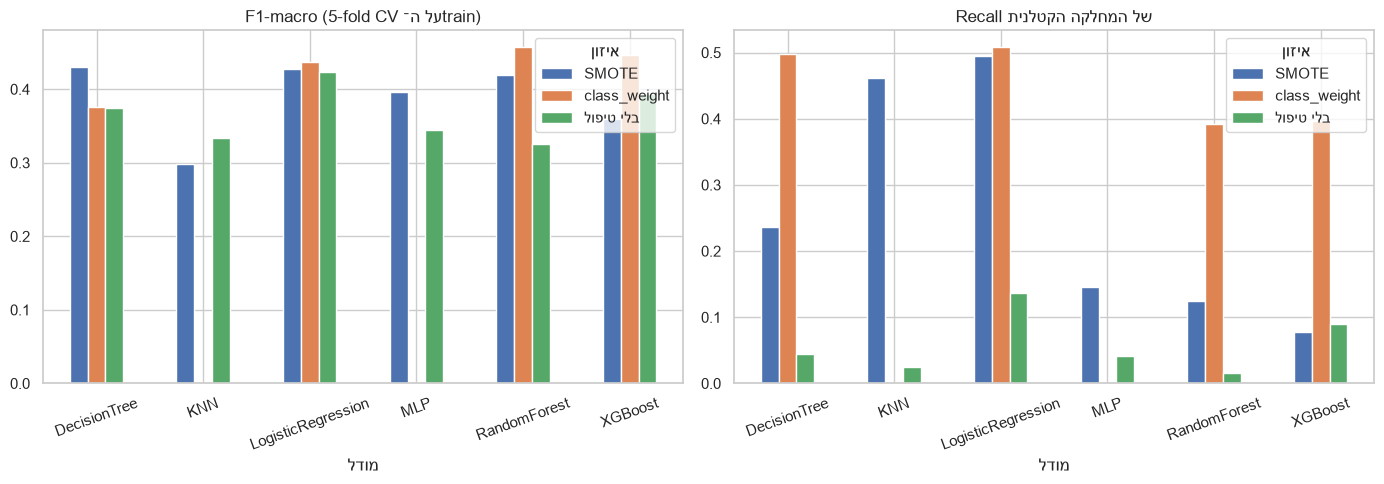

In [6]:
### CODE BY CLAUDE ###
pivot = results.pivot(index="model", columns="balance", values="f1_macro")
pivot_r = results.pivot(index="model", columns="balance", values="recall_fatal")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pivot.plot.bar(ax=axes[0], rot=20); axes[0].set_title("F1-macro (‏5-fold CV על ה־train)")
pivot_r.plot.bar(ax=axes[1], rot=20); axes[1].set_title("Recall של המחלקה הקטלנית")
for ax in axes:
    ax.set_xlabel("מודל"); ax.legend(title="איזון")
plt.tight_layout(); plt.savefig(FIGURES / "09_experiment1.png", dpi=150); plt.show()
####

<div dir="rtl">

**מה לשים לב (לפגישה):**
- בלי טיפול באיזון, ה־Recall של הקטלנית קרוב ל־0: המודלים פשוט לא מנבאים "קטלנית".
- class_weight ו־SMOTE מעלים מאוד את ה־Recall של הקטלנית, ובדרך כלל מורידים את ה־Accuracy. זה ה־trade-off משיעור 1.

</div>

<div dir="rtl">

## 5. ניסוי 2: כוונון היפר־פרמטרים לשני המודלים המובילים
`RandomizedSearchCV` עם `scoring="f1_macro"`, על ה־train בלבד.

</div>

In [7]:
### CODE BY CLAUDE ###
searches = {
    "RandomForest": (
        make_pipeline(RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE), "class_weight"),
        {"clf__n_estimators": [200, 400, 600], "clf__max_depth": [None, 10, 20, 30],
         "clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.3, 0.5]},
        {},
    ),
    "XGBoost": (
        make_pipeline(XGBClassifier(eval_metric="mlogloss", n_jobs=-1, random_state=RANDOM_STATE), "class_weight"),
        {"clf__n_estimators": [200, 400, 600], "clf__max_depth": [3, 4, 6, 8],
         "clf__learning_rate": [0.02, 0.05, 0.1], "clf__subsample": [0.7, 0.8, 1.0],
         "clf__colsample_bytree": [0.5, 0.7, 0.9], "clf__min_child_weight": [1, 5, 10]},
        {"clf__sample_weight": compute_sample_weight("balanced", y_train)},
    ),
}
best = {}
for name, (pipe, grid, fit_params) in searches.items():
    search = RandomizedSearchCV(pipe, grid, n_iter=15, scoring="f1_macro", cv=CV,
                                random_state=RANDOM_STATE, n_jobs=1)
    search.fit(X_train, y_train, **fit_params)
    best[name] = search
    print(f"{name}: F1-macro הכי טוב ב־CV = {search.best_score_:.3f}")
    print("    הפרמטרים:", {k.replace('clf__', ''): v for k, v in search.best_params_.items()})
####

RandomForest: F1-macro הכי טוב ב־CV = 0.452
    הפרמטרים: {'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 20}


XGBoost: F1-macro הכי טוב ב־CV = 0.460
    הפרמטרים: {'subsample': 0.8, 'n_estimators': 400, 'min_child_weight': 10, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


<div dir="rtl">

## 6. הערכה סופית על ה־test
פעם אחת בלבד, אחרי שכל ההחלטות התקבלו על ה־train.

</div>

In [8]:
### CODE BY CLAUDE ###
test_rows = []
for name, search in best.items():
    proba = search.predict_proba(X_test)
    pred = proba.argmax(axis=1)
    test_rows.append({"model": name,
                      "f1_macro": f1_score(y_test, pred, average="macro"),
                      "recall_fatal": recall_score(y_test, pred, labels=[0], average="macro"),
                      "pr_auc": pr_auc_macro(y_test, proba),
                      "accuracy": (pred == y_test).mean()})
test_results = pd.DataFrame(test_rows).round(3).rename(columns=COLS_HE)
test_results.to_csv(FIGURES / "test_results.csv", index=False, encoding="utf-8-sig")
test_results
####

,מודל,F1-macro,Recall קטלנית,PR-AUC,Accuracy
0,RandomForest,0.446,0.462,0.442,0.602
1,XGBoost,0.458,0.238,0.446,0.667


המודל שנבחר: XGBoost
              precision    recall  f1-score   support

      קטלנית      0.198     0.237     0.216        80
         קשה      0.334     0.375     0.354       301
         קלה      0.827     0.785     0.805      1035

    accuracy                          0.667      1416
   macro avg      0.453     0.466     0.458      1416
weighted avg      0.687     0.667     0.676      1416



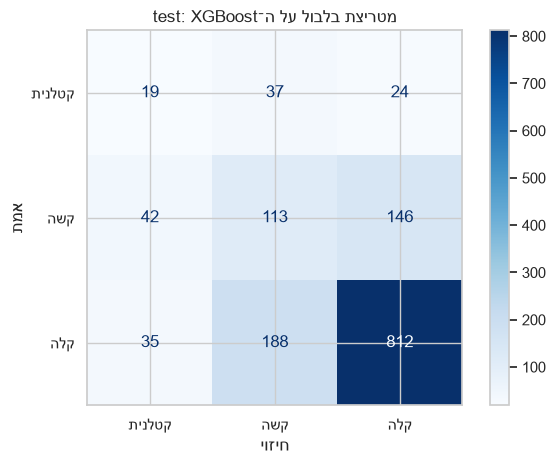

In [9]:
### CODE BY CLAUDE ###
# המודל הסופי נבחר לפי ציון ה־CV על ה־train, אף פעם לא לפי ה־test
best_name = max(best, key=lambda n: best[n].best_score_)
final = best[best_name].best_estimator_
pred = final.predict(X_test)
print("המודל שנבחר:", best_name)
print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASS_NAMES).plot(cmap="Blues")
plt.title(f"מטריצת בלבול על ה־test: {best_name}")
plt.xlabel("חיזוי"); plt.ylabel("אמת")
plt.tight_layout(); plt.savefig(FIGURES / "10_confusion_matrix.png", dpi=150); plt.show()
####

<div dir="rtl">

## 7. הזזת סף לקטלנית (שיעור 1)
המודל נותן הסתברות לכל מחלקה. ברירת המחדל: לבחור את הגבוהה ביותר.
כאן מכריזים "קטלנית" כבר כשההסתברות שלה עוברת סף נמוך יותר, ובודקים מה קורה ל־Recall ול־Precision שלה.
⚠️ בפרויקט עצמו את הסף בוחרים על validation (או CV) ולא על ה־test. כאן זה רק להמחשה של ה־trade-off.

</div>

In [10]:
### CODE BY CLAUDE ###
proba = final.predict_proba(X_test)
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1]:
    pred_t = proba.argmax(axis=1)
    pred_t[proba[:, 0] >= t] = 0
    rows.append({"סף": t,
                 "Recall קטלנית": recall_score(y_test, pred_t, labels=[0], average="macro"),
                 "Precision קטלנית": ((pred_t == 0) & (y_test == 0)).sum() / max((pred_t == 0).sum(), 1),
                 "F1-macro": f1_score(y_test, pred_t, average="macro")})
pd.DataFrame(rows).round(3)
####

,סף,Recall קטלנית,Precision קטלנית,F1-macro
0,0.50,0.238,0.198,0.458
1,0.40,0.238,0.186,0.455
2,0.30,0.312,0.159,0.444
3,0.20,0.475,0.139,0.426
4,0.15,0.550,0.122,0.402
5,0.10,0.712,0.115,0.374


<div dir="rtl">

## 8. פרשנות: אילו פיצ'רים הכי חשובים?

</div>

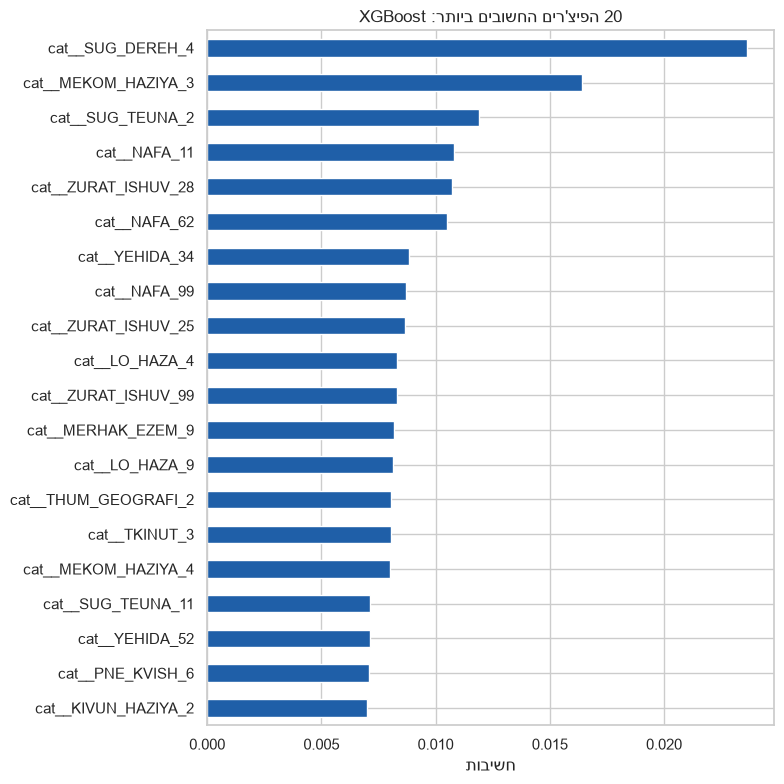

cat__SUG_DEREH_4        0.023633
cat__MEKOM_HAZIYA_3     0.016417
cat__SUG_TEUNA_2        0.011888
cat__NAFA_11            0.010795
cat__ZURAT_ISHUV_28     0.010718
cat__NAFA_62            0.010507
cat__YEHIDA_34          0.008833
cat__NAFA_99            0.008718
cat__ZURAT_ISHUV_25     0.008658
cat__LO_HAZA_4          0.008327
cat__ZURAT_ISHUV_99     0.008303
cat__MERHAK_EZEM_9      0.008189
cat__LO_HAZA_9          0.008140
cat__THUM_GEOGRAFI_2    0.008042
cat__TKINUT_3           0.008036
cat__MEKOM_HAZIYA_4     0.007992
cat__SUG_TEUNA_11       0.007147
cat__YEHIDA_52          0.007143
cat__PNE_KVISH_6        0.007073
cat__KIVUN_HAZIYA_2     0.007017
dtype: float32

In [11]:
### CODE BY CLAUDE ###
feature_names = final.named_steps["prep"].get_feature_names_out()
importances = pd.Series(final.named_steps["clf"].feature_importances_, index=feature_names)
top = importances.sort_values(ascending=False).head(20)
ax = top[::-1].plot.barh(figsize=(8, 8), color="#1f5fa8")
ax.set_title(f"20 הפיצ'רים החשובים ביותר: {best_name}")
ax.set_xlabel("חשיבות")
plt.tight_layout(); plt.savefig(FIGURES / "11_feature_importance.png", dpi=150); plt.show()
top
####

<div dir="rtl">

## 9. ניתוח שגיאות: על אילו תאונות קטלניות המודל טעה?
משווים את הקטלניות שהמודל **פספס** לאלה שהוא **תפס**, בכמה פיצ'רים מרכזיים.

</div>

In [12]:
### CODE BY CLAUDE ###
fatal_test = X_test[y_test == 0].copy()
fatal_test["נתפסה"] = pred[y_test.values == 0] == 0
print(f"תאונות קטלניות ב־test: {len(fatal_test)}, המודל תפס: {fatal_test['נתפסה'].sum()}")
for col in ["SUG_DEREH", "YOM_LAYLA", "SUG_TEUNA", "HAS_ROAD_NUMBER"]:
    print(f"\n{col}: אחוז מהתאונות הקטלניות בכל קוד, נתפסו מול פוספסו")
    print(pd.crosstab(fatal_test[col], fatal_test["נתפסה"], normalize="columns").mul(100).round(0)
          .rename(columns={True: "נתפסו", False: "פוספסו"}))
####

תאונות קטלניות ב־test: 80, המודל תפס: 19

SUG_DEREH: אחוז מהתאונות הקטלניות בכל קוד, נתפסו מול פוספסו
נתפסה      פוספסו  נתפסו
SUG_DEREH               
1            18.0   11.0
2            28.0   11.0
3            16.0   11.0
4            38.0   68.0

YOM_LAYLA: אחוז מהתאונות הקטלניות בכל קוד, נתפסו מול פוספסו
נתפסה      פוספסו  נתפסו
YOM_LAYLA               
1            54.0   53.0
5            46.0   47.0

SUG_TEUNA: אחוז מהתאונות הקטלניות בכל קוד, נתפסו מול פוספסו
נתפסה      פוספסו  נתפסו
SUG_TEUNA               
1            31.0   32.0
2            30.0    5.0
3             3.0   21.0
4             8.0    0.0
5            10.0   16.0
8             7.0    5.0
9             3.0    5.0
10            7.0    5.0
11            2.0    5.0
15            0.0    5.0

HAS_ROAD_NUMBER: אחוז מהתאונות הקטלניות בכל קוד, נתפסו מול פוספסו
נתפסה            פוספסו  נתפסו
HAS_ROAD_NUMBER               
0                  46.0   21.0
1                  54.0   79.0


<div dir="rtl">

## 10. ניסוי 3: בעיה בינארית, חמורה (קטלנית + קשה) מול קלה
שאלה: האם קל יותר להבדיל בין "חמורה" ל"קלה", מאשר להפריד גם בין קטלנית לקשה?

</div>

In [13]:
### CODE BY CLAUDE ###
yb_train = (y_train <= 1).astype(int)   # 1 = קטלנית או קשה
yb_test = (y_test <= 1).astype(int)
bin_rows = []
for name in ["LogisticRegression", "RandomForest", "XGBoost"]:
    model = make_models("class_weight")[name]
    pipe = make_pipeline(model, "class_weight")
    fit_params = {"clf__sample_weight": compute_sample_weight("balanced", yb_train)} if name == "XGBoost" else {}
    res = cross_validate(pipe, X_train, yb_train, cv=CV, params=fit_params,
                         scoring={"f1_macro": "f1_macro", "recall_severe": "recall", "pr_auc": "average_precision"})
    bin_rows.append({"מודל": name, "F1-macro": res["test_f1_macro"].mean(),
                     "Recall חמורה": res["test_recall_severe"].mean(), "PR-AUC": res["test_pr_auc"].mean()})
pd.DataFrame(bin_rows).round(3)
####

,מודל,F1-macro,Recall חמורה,PR-AUC
0,LogisticRegression,0.636,0.615,0.485
1,RandomForest,0.642,0.545,0.494
2,XGBoost,0.636,0.577,0.492


<div dir="rtl">

## 11. ניסוי 4: מה קורה אם משאירים את 1,235 התאונות בלי פרטי דרך?
ב־EDA (סעיף 7) ראינו ש־77% מהן "קשות". אם משאירים אותן, המודל לומד את הארטיפקט, והציון "מתנפח".

</div>

In [14]:
### CODE BY CLAUDE ###
X_all, y_all = get_xy(load_raw(), drop_missing_details=False)
y_all = y_all - 1
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
art_rows = []
for label, (Xt, yt) in {"בלי השורות האלה (הניסוי הראשי)": (X_train, y_train),
                        "עם השורות האלה": (Xa_train, ya_train)}.items():
    pipe = make_pipeline(make_models("class_weight")["XGBoost"], "class_weight")
    res = cross_validate(pipe, Xt, yt, cv=CV, scoring=SCORING,
                         params={"clf__sample_weight": compute_sample_weight("balanced", yt)})
    art_rows.append({"הדאטה": label, "שורות": len(Xt),
                     **{COLS_HE[m]: res[f"test_{m}"].mean() for m in SCORING}})
pd.DataFrame(art_rows).round(3)
####

,הדאטה,שורות,F1-macro,Recall קטלנית,PR-AUC,Accuracy
0,בלי השורות האלה (הניסוי הראשי),5664,0.447,0.396,0.455,0.611
1,עם השורות האלה,6652,0.520,0.457,0.568,0.668


<div dir="rtl">

**מה לראות:** עם השורות האלה הציון גבוה יותר, בעיקר כי קל לזהות "קשה" לפי פרטים חסרים. זה לא שיפור אמיתי,
ולכן הניסוי הראשי בלעדיהן. בדו"ח זה ממצא טוב לסעיף ניתוח השגיאות / איכות הדאטה.

</div>

<div dir="rtl">

## סיכום ושאלות לפגישה
1. איזה מודל ניצח, ולמה (עצים מול לוגיסטית בדאטה טבלאי עם הרבה קטגוריות)?
2. class_weight מול SMOTE: מה עבד טוב יותר, ומה המחיר ב־Accuracy?
3. איזה סף הייתם בוחרים לקטלנית, ולמה? (מה חשוב יותר: לפספס תאונה קטלנית, או התראת שווא?)
4. אילו פיצ'רים הכי חשובים, והאם זה הגיוני (לפי המילון)?
5. בהגנה ישנו פרמטרים: נסו לשנות `max_depth`, `n_neighbors` של KNN או `k_neighbors` של SMOTE, ולחזות מה יקרה לפני שמריצים.

</div>